# Telco Customer Churn Projesi

Projenin amacı `Churn`değişkenini kullanarak müşterilerin ayrılmış olup olmadığını sınıflandırmak.Gerçekten ayrılmıl müşterileri kaçırmamak ve ayrılmayacak müşteriler için verilen yanlış alarmlar sayısını azalatmak.Bu veri daha önceden elde edilmiş sonuçlar çerçevesinde geliştirilmiş bir sınıflandırma çalışmasıdır.Şirketin müşterileri izleyen bir zaman serisi olmadığı için gelecek tahmini olarak kullanılmaz

- `Churn` pozitif sonucu Yes.

- `Yanlış Negatif` aslında gerçekleşmiş olaya modelin gerçekleşmedi demesidir.Örnek olarak ayrılmış müşteriye ayrılmadı demesi.

- `Yanlış Pozitif` ise gerçekleşmemiş olaya modelin gerçekleşdi demesidir.Örnek olarak ayrılmamış müşteriye ayrılmış demesi.

- Recall öncelikli olmasının sebebi ayrılmış müşteriyi kaçırmamaktır.Ama bi yandan da diğer metrik olarak Precision kontrol edilecek.

| Sütun | Anlamı | Türü |
| --- | --- | --- |
|customerID| Müşterinin ID değeri|Metin|
|gender|Müşterinin Cinsiyeti|Metin|
|SeniorCitizen|Müşterinin yaşlı olup olmadığını gösterir(0:Hayır 1:Evet)|Sayısal|
|Partner|Müşterinin partneri var mı yok mu onu gösterir(evet hayır)|Metin|
|Dependents|Müşterinin bakmakla yükümlü olduğu birileri var mı yok mu onu gösterir|Metin|
|tenure|Kaç ay müşterinin şirketle çalıştığını gösterir|Sayısal|
|PhoneService|Telefon servisi alıp almadığını gösterir|Metin|
|MultipleLines|Birkaç telefon hattı var mı onu gösterir|Metin|
|InternetService|İnternet Servisi varsa hangi tür olduğu yoksa hayır yazan değer|Metin|
|OnlineSecurity|Online güvenlik desteği almış mı almamış mı|Metin|
|OnlineBackup|Online yedekleme desteği alıp almadığını gösterir|Metin|
|DeviceProtection|İnternet cihazları için koruma destği almış mı onu gösterir|Metin|
|TechSupport|Teknoloji desteği almış mı almamış mı|Metin|
|StreamingTV|İnternet servisi üzerinden yayın izleme yapıyor mu|Metin|
|StreamingMovies|İnternet servisi kullanarak filmleri izliyor mu|Metin|
|Contract|Sözleşme Türü|Metin|
|PaperlessBilling|Kağıtsız fatura mı seçmiş|Metin|
|PaymentMethod|Fatura ödeme türü|Metin|
|MonthlyCharges|Tüm servisler sonucu müşteriden aylık alınan miktar|Sayısal|
|TotalCharges|Bugüne kadar yansıtılmış toplam tutar|Metin|
|Churn|Müşteri ayrılmış mı|Metin|






Projenin Bilgileri:
- https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv

- 21.10.2026

- Telco-Customer-Churn.csv


## Aşama 2 — Veri denetimi ve kilitli test kümesi

- İlk olarak `pandas`kütüphanesini yükleyip csv dosyasını dataframe'e çeviriyoruz

- head() fonksiyonunu kullanarak veri setinin ilk 5 satırına göz gezdiriyoruz

In [1]:
import pandas as pd
import numpy as np 

churn_data = pd.read_csv("Telco-Customer-Churn.csv")

churn_data.head()

Veri setimizizin yapısını anlamak için ilk olarak shape fonksiyonunu kullanıp kaç satır ve sütundan oluştuğunu kontrol ediyoruz.Çıkan sonuçta ise 7043 satır ve 21 sütun gözüküyor bu bizim veri setimizin şekli

In [2]:
churn_data.shape

(7043, 21)

info() fonksiyonu veri setimizi tanımak için kullanbileceğimiz en etkili fonksiyonlardan çünkü aynı anda bir çok bilgiyi bize verebiliyor.Bu bilgiler:

- Sütun ve satır
- Sütun isimleri
- Boş olmayan değer sayısı
- Veri tipi

Böylelikle hangi sütunun hangi veri tipinde değer tutuğunu ve basitçe kaç eksik değere sahip olduğunu görebiliyoruz

In [3]:
churn_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Sonrasında şöyle bir şey fark ediyoruz.Burada TotalCharges sütunu aslında metin değeri olarak gözüküyor ama aslında bu parasal bir ifade olduğu için bizim bunu sayısal bir ifadeye dönüştürmemiz daha sağlıklı olur.Aşağıda ise bu sütunu sayısal değere çevirip çeviremediği değerleri NaN olarak yazıyor

In [4]:
churn_data["TotalCharges"] = pd.to_numeric(churn_data["TotalCharges"], errors="coerce")

Tekrar sütun türlerini kontrol ettiğimizde ise değişimin gerçekleştiğini görmüş olduk

In [5]:
churn_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`churn`değerinin yüzdesel dağılımını görmek için values_counts() fonksiyonu kullanıp `normalize=True` parametresiyle yüzdesel bir şekle çevirdik. No değeri %73.5,Yes değeri ise %26.5 olarak önümüze çıktı

In [6]:
churn_data["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

Sonrasında ise eksik değerler var mı diye kontrol ettik ve veri setimizde eksik değerler olduğıunu gördük.Bu eskik değerlerin hepsi metin türünden sayısal türe çevirdiğimiz `TotalCharges`sütununda bulunuyor

In [7]:
churn_data.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Burada ise TotalCharges değerinin eksik olduğu satırları kontrol ettik ve inceledik.Çeviremediği değerler cidden boş mu yoksa başka bir mi var

In [8]:
display(churn_data[churn_data["TotalCharges"].isna()]["TotalCharges"])

missing_index = churn_data[churn_data["TotalCharges"].isna()].index


488    NaN
753    NaN
936    NaN
1082   NaN
1340   NaN
3331   NaN
3826   NaN
4380   NaN
5218   NaN
6670   NaN
6754   NaN
Name: TotalCharges, dtype: float64

Sonrasında ise ham veri setinde bu eksik değerler nasıl diye bakınca hepsinin aslında boş değer olduğunu görüyoruz ve bunları numeric çevirme işlemi yapınca missing value olarak döndüğü kesinleşiyor

In [9]:
df = pd.read_csv("Telco-Customer-Churn.csv")

df.iloc[missing_index]["TotalCharges"]


488      
753      
936      
1082     
1340     
3331     
3826     
4380     
5218     
6670     
6754     
Name: TotalCharges, dtype: str

Burada ise metinsel sütunların sahip olduğu değerleri ve sayılarını gördük böylelikle aykırı bir durum var mı kontrol etmiş olduk

In [10]:
str_columns = churn_data.select_dtypes(include=["object", "string"]).columns.tolist()

for i in str_columns:
    print(churn_data[i].value_counts())
    print("\n")

customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64


gender
Male      3555
Female    3488
Name: count, dtype: int64


Partner
No     3641
Yes    3402
Name: count, dtype: int64


Dependents
No     4933
Yes    2110
Name: count, dtype: int64


PhoneService
Yes    6361
No      682
Name: count, dtype: int64


MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64


DeviceProtection
No                     3095


Tekrarlanan bir satır olup olmadığını kontrol ettiğimizde hiçbir satırın tekrarlamadığını görmüş olduk

In [11]:
churn_data.duplicated().sum()

np.int64(0)

Sonrasında customerID değerlerinden bir tekrar var mı diye spesifik olarak bir kontrol sağladığımızda da bir sıkıntı göremedik.Hiç bir tekrar eden bir sütun yok

In [12]:
churn_data["customerID"].duplicated().sum()

np.int64(0)

Veri setimizden customerID sütununu çıkardık çünkü bu sütun asla tahmin girdisi olarak kullanılmayacak

In [13]:
churn_data.drop(columns=["customerID"],inplace=True)

Şimdi modelimizi `StratifiedShuffleSplit`kullanarak bölüyoruz.Bunu yapmamızın en büyük sebebi churn yüzdesine göre eşit bir bölünmenin yapılmasını istememiz.Bunun sonucu olarak ayırdığımız tüm setler %73.5 No,%26.5 Yes oranına sahip olucak.

Test verisinin önceden ayrılmasının sebebi nihayi modelin final değerlendirmesi olmasıdır.Ayrıca test verisinin sonucuna göre model seçmiyoruz çünkü bu sefer bu bizim model seçme kararımızı etkiler ve değerlendirme ölçütünden çıkmış olur

In [14]:
from sklearn.model_selection import StratifiedShuffleSplit

sss = StratifiedShuffleSplit(n_splits=1,test_size=.2,train_size=.8,random_state=42)

for train_index,test_index in sss.split(churn_data,churn_data["Churn"]):
    X_train,X_test = churn_data.iloc[train_index],churn_data.iloc[test_index]
    y_train,y_test = churn_data["Churn"].iloc[train_index],churn_data["Churn"].iloc[test_index]

Veri setlerinin oranlarını kontrol ederek herhangi bir problemin olmadığını görmüş oluyoruz.Split sonucunda tüm veri seti Chrun değerinin oranına göre bölünmüş.

In [15]:
print(X_train["Churn"].value_counts(normalize=True).mul(100).round(2))
print(X_test["Churn"].value_counts(normalize=True).mul(100).round(2))
print(y_train.value_counts(normalize=True).mul(100).round(2))
print(y_test.value_counts(normalize=True).mul(100).round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Bura ise ne kadar değere sahip olduğunu kontrol etmiş olduk

In [16]:
print(X_train["Churn"].value_counts())
print(X_test["Churn"].value_counts())
print(y_train.value_counts())
print(y_test.value_counts())

Churn
No     4139
Yes    1495
Name: count, dtype: int64
Churn
No     1035
Yes     374
Name: count, dtype: int64
Churn
No     4139
Yes    1495
Name: count, dtype: int64
Churn
No     1035
Yes     374
Name: count, dtype: int64


|Kontrol|Gözlem|Alınan karar|
|---|---|---|
|Eksik değer|TotalCharges alanında 11 boş değer var|Kıdemi 0 olan bu kayıtların değerini model ön işlemesinde 0 ile doldurmak|
|Tekrar eden satırlar|Tekrar eden satır yok|Ek işlem gerekmiyor|
|Churn dağılımı|%73,5 No ve %26,5 Yes|Sınıf oranını koruyan bölme yapmak|


X veri setlerindeki Churn değerlerini kaldırdık ileri aşamalar için.Bu değerler y veri setlerindeki değerler olarak tutuluyor

In [17]:
X_train.drop(columns=["Churn"],inplace=True)
X_test.drop(columns=["Churn"],inplace=True)

## Aşama 3 — Keşifsel veri analizi

Grafik çizimleri yapmak için matplotlib kütüphanesini yüklüyoruz

In [18]:
import matplotlib.pyplot as plt

Sonrasında analiz yapabilmek için X_train veri setini kopyalayıp kaldırdığımız churn değerlerini y_train setini kullanarak ekliyoruz ve EDA için bir veri seti oluşturuyoruz

In [19]:
data = X_train.copy()

data["Churn"] = y_train

Kontrol edip bir sorun olmadığını görüyoruz

In [20]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,No
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,No
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,No
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,No


Sözleşme türlerine göre churn değerini gruplandırmasını yapıyoruz bunları yüzdelik olarak görüyoruz.En yüksek ayrılma yüzdesinin ay ay ödeme yapanlar arasınbda olduğunu görmüş olduk

In [21]:
churn_rate_by_contract = data.groupby("Contract")["Churn"].value_counts(normalize=True).mul(100).round(2).unstack()
churn_rate_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.25,42.75
One year,88.92,11.08
Two year,97.13,2.87


burada ise adet olarak bu değerleri görüyoruz.En yüksek değerin aylık ödeme olduğunu ve 1326 kişinin ayrıldığını görüyoruz

In [22]:
data.groupby("Contract")["Churn"].value_counts().unstack().T

Contract,Month-to-month,One year,Two year
Churn,,,
No,1776,1043,1320
Yes,1326,130,39


Burada ise verinin oransal değerlerini kullanarak bir çubuk tablosu oluşturuyoruz.Görsel olarak bu oranları görmek daha iyi kavramamıza yardımcı oluyor

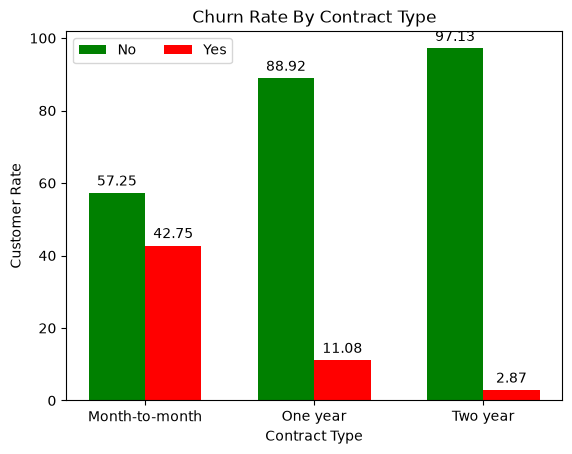

In [23]:

contract_plot = plt.grouped_bar(
    churn_rate_by_contract,
    group_spacing=1,
    colors=["Green","Red"] 
)
for container in contract_plot.bar_containers:
    plt.bar_label(container, padding=3)

plt.title("Churn Rate By Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customer Rate")
plt.legend(ncols=2)


**Gözlem:** Eğitim verisinde `Churn = Yes` oranı aylık sözleşmede %42,75, bir yıllık sözleşmede %11,08 ve iki yıllık sözleşmede %2,87. Aylık sözleşme grubunda ayrılma oranı en yüksek.

**Olası yorum:** Aylık sözleşmelerin daha esnek olması veya bu sözleşmeyi seçen müşterilerin farklı özellikler taşıması gözlenen farkla ilişkili olabilir. Bu karşılaştırma, sözleşme türünün tek başına ayrılmaya neden olduğunu kanıtlamaz.

Kıdem sayısına göre churn oranına kontrol ediyoruz.Kıdem seviyesi artıkça ayrılma oranı düşüyor olması gerektiğini düşünüyor ve baktığımızda çıkan değerlerde öyle duruyor fakat aralarda farklı şeyler çıkabilir

In [24]:

churn_by_tenure = data.groupby("tenure")["Churn"].value_counts(normalize=True).mul(100).round(2).unstack()
churn_by_tenure

Churn,No,Yes
tenure,,
0,100.00,NaN
1,38.40,61.60
2,50.80,49.20
3,54.00,46.00
4,56.43,43.57
...,...,...
68,90.48,9.52
69,90.67,9.33
70,90.91,9.09


Sonrasında ise kıdem sayısına göre kaç müşteri var onu kontrol ediyoruz ve aslında 0. ayda Yes değerinin NaN olmasının sebebi 8 kişinin hiç birinin Yes değerine sahip olmaması

In [25]:
data.groupby("tenure")["tenure"].value_counts()

tenure
0       8
1     487
2     187
3     150
4     140
     ... 
68     84
69     75
70     99
71    142
72    292
Name: count, Length: 73, dtype: int64

Sonrasında kıdem sayısına göre churn oranı grafiği çiziyoruz. Ay sayısı arttıkça `Churn = Yes` oranı genel olarak düşüyor; `No` oranı ise ters yönde artıyor. Bunun olası bir açıklaması, uzun süredir müşteri olanların hizmete alışması olabilir. Bu grafik tek başına neden-sonuç ilişkisi göstermez.


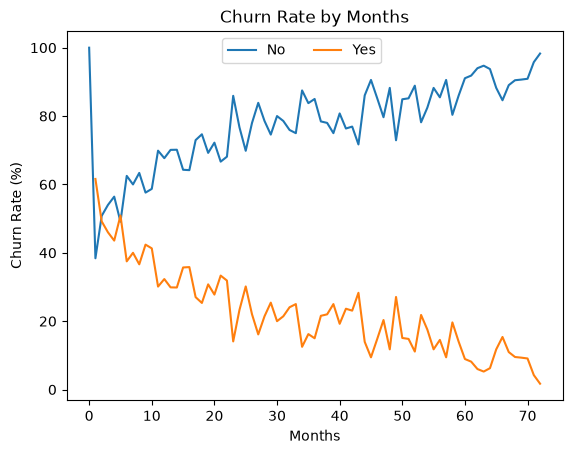

In [26]:

tenure_rate = plt.plot(churn_by_tenure)
plt.xlabel("Months")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Months")
plt.legend(["No","Yes"],loc="upper left",ncols=2,bbox_to_anchor=(.3,1))


Sonrasında ise aylık ücretler ödemelerini 6 parçaya ayrılmış aralıklara alıyoruz ve bunu veri setine ekliyoruz bu aralıklara göre gruplandırma yapıp churn sayılarını görüyoruz.

In [27]:
data["MonthlyCharges_Range"] = pd.cut(data["MonthlyCharges"],6)

monthly_charges_range = data.groupby("MonthlyCharges_Range")["Churn"].value_counts().unstack()


In [28]:


_ = data.groupby("MonthlyCharges_Range")["Churn"].value_counts(normalize=True).mul(100).round(2).unstack()
_


Churn,No,Yes
MonthlyCharges_Range,,
"(18.3, 35.125]",89.28,10.72
"(35.125, 51.85]",70.23,29.77
"(51.85, 68.575]",85.03,14.97
"(68.575, 85.3]",62.18,37.82
"(85.3, 102.025]",61.27,38.73
"(102.025, 118.75]",74.96,25.04


Sonrasında ise bu gördüğümüz churn oranları grafiğe döküp geniş çaplı bir inceleme yapıyoruz.

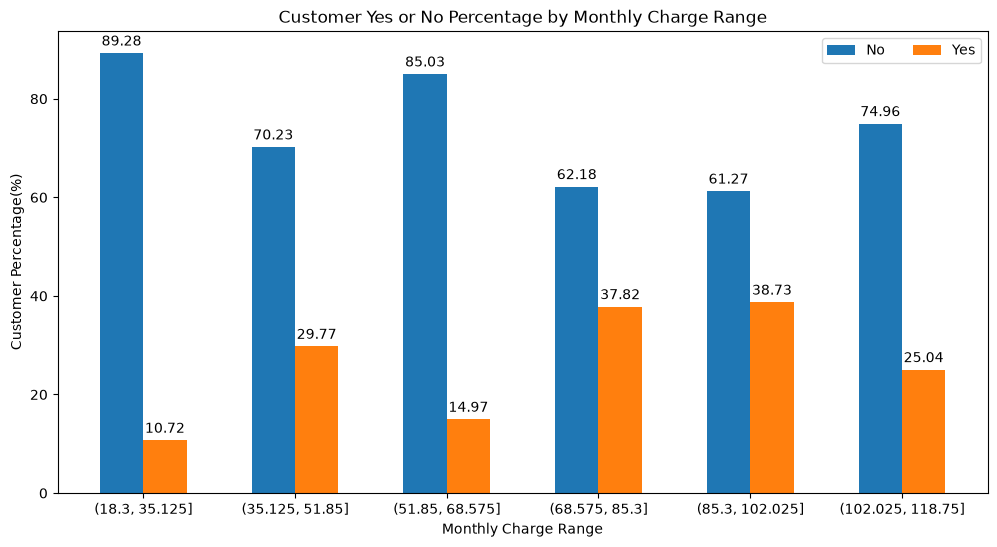

In [29]:
plt.figure(figsize=(12,6))
monthly_charges_range_plot = plt.grouped_bar(_)

for container in monthly_charges_range_plot.bar_containers:
    plt.bar_label(container, padding=3)

plt.xlabel("Monthly Charge Range") 
plt.ylabel("Customer Percentage(%)")  
plt.title(" Customer Yes or No Percentage by Monthly Charge Range ")

plt.legend(ncols=2)
plt.show()

**Gözlem:** Eğitim verisinde `Churn = Yes` oranı 85,3–102,025 aylık ücret aralığında %38,73 ile en yüksek, 18,3–35,125 aralığında %10,72 ile en düşük. En yüksek ücret aralığında oran %25,04 olduğundan ücret arttıkça ayrılma oranı düzenli biçimde artmıyor.

**Olası yorum:** Ücret aralıklarında alınan hizmetlerin veya müşteri profillerinin farklı olması bu oranlarla ilişkili olabilir. Bu sonuç, ücretin tek başına ayrılmaya neden olduğunu göstermez.

In [30]:
display(data["TotalCharges"].describe())
display(data["TotalCharges"].isna().sum())


count    5626.000000
mean     2302.604266
std      2279.173176
min        18.850000
25%       407.275000
50%      1398.125000
75%      3838.612500
max      8684.800000
Name: TotalCharges, dtype: float64

np.int64(8)

Burada ise teknoloji desteği değerlerine göre churn oranlarını gördük.internet servisi olmayanlar interneti servisi almayanları, geri kalanlar ise internet servisi olup teknoloji desteği almış mı almamış mı gösteriyor.Altındakş tablo ise sayılarını gösteriyor

In [31]:
display(data.groupby("TechSupport")["Churn"].value_counts(normalize=True).mul(100).round(2).unstack().T)
display(data.groupby("TechSupport")["Churn"].value_counts().unstack().T)

TechSupport,No,No internet service,Yes
Churn,,,
No,58.25,92.75,84.84
Yes,41.75,7.25,15.16


TechSupport,No,No internet service,Yes
Churn,,,
No,1614,1126,1399
Yes,1157,88,250


**Gözlem:** Eğitim verisinde `Churn = Yes` oranı internet hizmeti olup teknoloji desteği almayanlarda %41,75, teknoloji desteği alanlarda %15,16. İnternet hizmeti olmayan ayrı grupta oran %7,25.

**Olası yorum:** Teknoloji desteği durumu ile ayrılma arasındaki fark, müşterilerin hizmet kullanımı veya başka özellikleriyle ilişkili olabilir. İnternet hizmeti olmayanlar farklı bir müşteri grubu olduğu için bu oranı destek alan ve almayanlarla aynı koşullarda karşılaştırmıyorum; veriler teknoloji desteğinin tek başına ayrılmayı önlediğini kanıtlamaz.

Son olarak TotalCharges eksik değerlerini kontrol ettiğimizde güzel bir detay fark ediyoruz bu da tenure değerlerinin 0 olması.Yukarıda tenure 0 değerine sahip kişilerin hiç birinin TotalCharges değeri yok çünkü henüz fatura kesilmemiş olabilir.Bu değerleri 0 olarak doldurmak mantıklı olarak düşünüyorum


In [32]:
data[data["TotalCharges"].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MonthlyCharges_Range
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,...,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No,"(68.575, 85.3]"
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No,"(18.3, 35.125]"
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No,"(18.3, 35.125]"
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,...,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,"(51.85, 68.575]"
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No,"(18.3, 35.125]"
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,...,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,"(51.85, 68.575]"
6754,Male,0,No,Yes,0,Yes,Yes,DSL,Yes,Yes,...,Yes,No,No,Two year,Yes,Bank transfer (automatic),61.90,NaN,No,"(51.85, 68.575]"
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No,"(18.3, 35.125]"


In [33]:
data["TotalCharges"] = data["TotalCharges"].fillna(0)

In [34]:
data.info()

<class 'pandas.DataFrame'>
Index: 5634 entries, 3738 to 5639
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   gender                5634 non-null   str     
 1   SeniorCitizen         5634 non-null   int64   
 2   Partner               5634 non-null   str     
 3   Dependents            5634 non-null   str     
 4   tenure                5634 non-null   int64   
 5   PhoneService          5634 non-null   str     
 6   MultipleLines         5634 non-null   str     
 7   InternetService       5634 non-null   str     
 8   OnlineSecurity        5634 non-null   str     
 9   OnlineBackup          5634 non-null   str     
 10  DeviceProtection      5634 non-null   str     
 11  TechSupport           5634 non-null   str     
 12  StreamingTV           5634 non-null   str     
 13  StreamingMovies       5634 non-null   str     
 14  Contract              5634 non-null   str     
 15  PaperlessBilling 

## Aşama 4 — Ön işleme ve referans model

| Modeldeki rolü | Bu gruptaki sütunlar |
| --- | --- |
| Sayısal girdi | tenure,MonthlyCharges,TotalCharges|
| Kategorik girdi |PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,gender,SeniorCitizen,Partner,Dependents,PaymentMethod|
| Hedef | Churn|
| Kullanılmayacak |customerID|

`SeniorCitizen` Müşterinin yaşlı olup olmadığını gösteriyor 1 ve 0 değeri var bu da evet ya da hayır sonucu veriyor ondan dolayı kategori sınıfında

`TotalCharges`değeri ise sayısalda bir en başta bu değeri str den float bir değere çevirdik çünkü müşteriden alınan parayı temsil ediyor ve bu sayısal bir değer

Kategorik girdilere `OneHotEncoder` uygulayacağız çünkü kategoriler arasında bir sıralama yok bundan dolayı matematiksel bir hata olmasını istemiyoruz modelde.OneHotEncoder ise hepsini 0-1 değerlerine böler ve aralarında keyfi bir sıra olmaz

TotalCharges sütunundaki boşlukların hepsi yeni müşterilerin değerleri bundan dolayı 0 ile doldurmayı planlıyorum

Lojistik regresyon modelinde ölçeklendirme genellikle yararlıdır çünkü bu model sayıların büyüklüklerinden etkileniyor ve bu sadece eğitim seti katmanında yapılacak lojistik regresyon modeline özel fakat karar ağaçları ve random forest ölçeklendirme gerekmiyor

5 katlı çapraz doğrulamada her turda 4 kat eğitim, 1 kat doğrulama için kullanılır. Kategorik kodlayıcı kategorileri, ölçeklendirici ise ortalama ve standart sapmayı yalnızca o turun eğitim katlarından öğrenir. Öğrenilen aynı dönüşümler doğrulama katına uygulanır; doğrulama katından yeniden değer öğrenilmez. TotalCharges boşluklarını 0 ile doldurma işlemi de ön işleme pipeline’ında yapılır.


In [35]:
X_train[X_train["tenure"]==0][["tenure","Contract","MonthlyCharges","TotalCharges"]]

,tenure,Contract,MonthlyCharges,TotalCharges
6670,0,Two year,73.35,NaN
4380,0,Two year,20.00,NaN
3826,0,Two year,25.35,NaN
488,0,Two year,52.55,NaN
1082,0,Two year,25.75,NaN
1340,0,Two year,56.05,NaN
6754,0,Two year,61.90,NaN
3331,0,Two year,19.85,NaN


Öncelikle pipeline kısmını hallediyoruz ve burada sayısal ve kategorik kısımları ayırıyoruz sonrasında ise bunların nasıl bir pipelinedan geçeceğine karar veriyoruz.Aşağıda yapılan pipeline ise lojistik regresyon için yapılmış bir pipeline

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_features = ["tenure","MonthlyCharges","TotalCharges"]
numeric_transformer = Pipeline(
    steps=[("imputer",SimpleImputer(strategy="constant",fill_value=0)),("scaler",StandardScaler())]
)

categorical_features = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                         "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "gender", "SeniorCitizen", "Partner", "Dependents", "PaymentMethod"]
categorical_transformer = Pipeline(
    steps=[("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

Sonrasında ise treeler için bir pipeline yapıyoruz çünkü lojistik regresyon pipeline kısmında scaler kullandık fakat treeler için bu gerekli bir şey değil bundan dolayı 2 ayrı  transformer yapmış olduk

In [37]:

numeric_transformer_tree = Pipeline(
    steps=[("imputer",SimpleImputer(strategy="constant",fill_value=0))]
)

categorical_transformer_tree = Pipeline(
    steps=[("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_tree, numeric_features),
        ("cat", categorical_transformer_tree, categorical_features),
    ]
)

Sonrasında ise en basit karşılaştırma noktası için `DummyClassifier` kullanıyoruz bu bize en basit şekilde model tahmin yaparken her şeye No dese nasıl bir doğruluk verir onu gösteriyor.En sık tekrar eden değere göre yapıyor

In [38]:
from sklearn.dummy import DummyClassifier

clf_dummy = DummyClassifier(random_state=42,strategy="most_frequent")



Sonrasında ise karar verdiğimiz gibi 5 katmandan oluşan bir yapı oluşturmak için StratifiedKFold kullanıyoruz ve cross_val_score yöntemiyle doğruluk değerini modelleri kullanarak bakıyoruz

In [39]:
from sklearn.model_selection import StratifiedKFold,cross_val_score

skf = StratifiedKFold(n_splits=5)

cv_results = cross_val_score(clf_dummy,X_train,y_train,scoring="accuracy",cv=skf)

Çıkan 5 sonucun ortalaması %73.46 bu da çoğunluk sınıfını seçen referans modelin %73.46 oranında doğru olacağını söylüyor.Bu bizim için bir referans değeri

In [40]:
display(cv_results)
display(cv_results.mean())

array([0.73469388, 0.73469388, 0.73469388, 0.73469388, 0.73445826])

np.float64(0.7346467539058252)

burada ise recall değerine bakıyoruz ve modelin yes olan değerleri hiç bulamadığını görüyoruz ve bu gayet normal çünkü en çok tekrar eden değerin no olduğunu biliyoruz

In [41]:
from sklearn.metrics import recall_score,make_scorer

yes_recall = make_scorer(recall_score, pos_label="Yes")

cross_val_score(clf_dummy,X_train,y_train,scoring=yes_recall,cv=skf)

array([0., 0., 0., 0., 0.])

## Aşama 5 — Model karşılaştırması

Şimdi ilk modelimiz olan lojistik regresyonu kuruyoruz. Önce sütunlar için hazırladığımız dönüşümleri ve modeli aynı pipeline içinde birleştiriyoruz. Average precision (AP) için `Yes` sınıfının tahmin olasılıklarını kullanıyoruz. Beş katlı çapraz doğrulama sonunda her katın AP skoruna ve ortalamaya bakıyoruz.


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
log_reg = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", LogisticRegression(random_state=42))]
)

ap_scorer = make_scorer(
    average_precision_score,
    response_method="predict_proba",
    pos_label="Yes"
)

log_reg_cv = cross_val_score(log_reg,X_train,y_train,scoring=ap_scorer,cv=skf)

display(log_reg_cv)
display(log_reg_cv.mean())

array([0.70831862, 0.66177879, 0.67154299, 0.64251879, 0.62452852])

np.float64(0.6617375411884391)

Sonra bu aynı şeyi Cross validation kullanarak dummy için yapıyoruz. Sonra dummy classifier'ın da sonuçlarını aşağıda görmüş oluyoruz.

In [43]:
dummy_ap = cross_val_score(clf_dummy,X_train,y_train,scoring=ap_scorer,cv=skf)
display(dummy_ap,dummy_ap.mean())


array([0.26530612, 0.26530612, 0.26530612, 0.26530612, 0.26554174])

np.float64(0.2653532460941748)

Burada ise ikinci modelimiz olan decision tree'lere geçiyoruz. Sonra burada yine logistic regression modelinde yaptığımız gibi bir tree classifier pipeline kuruyoruz. Yine yapısal olarak birbirine benziyorlar. Sadece classifier kısmında decision tree classifier var. Sonrasında ise cross val score kullanarak aynı veriyi decision tree ile eğiterek AP skorunu kontrol ediyoruz ve aşağıda da onun sonuçlarını görmüş oluyoruz.

In [44]:

from sklearn.tree import DecisionTreeClassifier

tree_clf = Pipeline(
    steps=[("preprocessor", preprocessor_tree), ("classifier",DecisionTreeClassifier(random_state=42))]
)

tree_reg_cv = cross_val_score(tree_clf,X_train,y_train,scoring=ap_scorer,cv=skf)

display(tree_reg_cv,tree_reg_cv.mean())

array([0.37505601, 0.35880042, 0.37676609, 0.3781004 , 0.34781905])

np.float64(0.36730839485038336)

Decision Tree classifier bittiğine göre şimdi sıradaki modelimiz Random Forest classifier. birebir aynısını Random Forest için yapıyoruz. sonrasında Random Forest'ın değerlerini, AP değerini kontrol ediyoruz.

In [45]:

from sklearn.ensemble import RandomForestClassifier


forest_clf = Pipeline(
    steps=[("preprocessor", preprocessor_tree), ("classifier",RandomForestClassifier(random_state=42))]
)

forest_clf_cv = cross_val_score(forest_clf,X_train,y_train,scoring=ap_scorer,cv=skf)

display(forest_clf_cv,forest_clf_cv.mean())

array([0.65663069, 0.6356762 , 0.59595551, 0.59464837, 0.58529727])

np.float64(0.6136416060122295)

Yukarıda yalnızca average precision skoruna baktık. Modeli daha geniş değerlendirmek için recall, precision ve F2 ölçütlerini de ekliyoruz. Bu ölçütlerde pozitif sınıfı `Yes` olarak belirleyip lojistik regresyonu aynı beş katlı düzenle yeniden değerlendiriyoruz.


In [46]:
from sklearn.metrics import recall_score,precision_score,fbeta_score
from sklearn.model_selection import cross_validate

recall_scorer = make_scorer(
    recall_score,
    pos_label="Yes"
)

precision_scorer = make_scorer(
    precision_score,
    pos_label="Yes"
)

fbeta_scorer = make_scorer(
    fbeta_score,
    pos_label="Yes",
    beta=2
)

all_scorer = {
    "recall":recall_scorer,
    "precision":precision_scorer,
    "f2":fbeta_scorer,
    "AP":ap_scorer
}

log_reg_all_scorer_cv = cross_validate(log_reg,X_train,y_train,scoring=all_scorer,cv=skf)

display(log_reg_all_scorer_cv)



{'fit_time': array([0.03350115, 0.03161788, 0.03281021, 0.03113317, 0.03070498]),
 'score_time': array([0.02259588, 0.02143693, 0.02218604, 0.02182102, 0.021734  ]),
 'test_recall': array([0.59531773, 0.52508361, 0.54180602, 0.53846154, 0.54180602]),
 'test_precision': array([0.71774194, 0.65966387, 0.66666667, 0.62403101, 0.62307692]),
 'test_f2': array([0.61634349, 0.5474198 , 0.5628909 , 0.55364512, 0.55631868]),
 'test_AP': array([0.70831862, 0.66177879, 0.67154299, 0.64251879, 0.62452852])}

Sonra aynı skorlama yapısını tree ve forest için de kullanıyoruz.

In [47]:
tree_reg_all_scorer_cv = cross_validate(tree_clf,X_train,y_train,scoring=all_scorer,cv=skf)
display(tree_reg_all_scorer_cv)

{'fit_time': array([0.0378139 , 0.03725004, 0.03691292, 0.03668404, 0.03734493]),
 'score_time': array([0.02187324, 0.02262974, 0.02156711, 0.02140093, 0.02175903]),
 'test_recall': array([0.52508361, 0.46822742, 0.47491639, 0.49832776, 0.46488294]),
 'test_precision': array([0.47432024, 0.46357616, 0.5       , 0.49013158, 0.44126984]),
 'test_f2': array([0.5140799 , 0.46728972, 0.47972973, 0.49666667, 0.45996029]),
 'test_AP': array([0.37505601, 0.35880042, 0.37676609, 0.3781004 , 0.34781905])}

In [48]:
forest_clf_all_scorer_cv = cross_validate(forest_clf,X_train,y_train,scoring=all_scorer,cv=skf)
display(forest_clf_all_scorer_cv)

{'fit_time': array([0.27080178, 0.30135393, 0.26998019, 0.26761389, 0.26951122]),
 'score_time': array([0.04758596, 0.0474031 , 0.04698777, 0.04665399, 0.04723978]),
 'test_recall': array([0.52842809, 0.46488294, 0.4916388 , 0.46822742, 0.45819398]),
 'test_precision': array([0.65289256, 0.64351852, 0.62820513, 0.58823529, 0.60087719]),
 'test_f2': array([0.54937413, 0.49220963, 0.51398601, 0.48814505, 0.48103933]),
 'test_AP': array([0.65663069, 0.6356762 , 0.59595551, 0.59464837, 0.58529727])}

Burada ise yukarıda aldığımız tüm skorlama değerlerini bir tane data frame'de topluyoruz. Ama bunların ortalama değerlerini alıyoruz ve her modelin AP, AP standard deviation'ı, recall'u, precision'ı ve F2 skorunu bir data frame olarak döndürüyoruz ve bu bizim inceleme ve karar vermede bize yardımcı olacak.

In [49]:
model_results = {
    "Lojistik regresyon": log_reg_all_scorer_cv,
    "Karar ağacı": tree_reg_all_scorer_cv,
    "Random Forest": forest_clf_all_scorer_cv,
}

comparison = pd.DataFrame([
    {
        "Model": model_name,
        "AP": results["test_AP"].mean(),
        "AP_Std":results["test_AP"].std(),
        "Recall": results["test_recall"].mean(),
        "Precision": results["test_precision"].mean(),
        "F2": results["test_f2"].mean(),
    }
    for model_name, results in model_results.items()
])

display(comparison.round(3))

,Model,AP,AP_Std,Recall,Precision,F2
0,Lojistik regresyon,0.662,0.028,0.548,0.658,0.567
1,Karar ağacı,0.367,0.012,0.486,0.474,0.484
2,Random Forest,0.614,0.028,0.482,0.623,0.505


Tabloda başlangıç ayarlarıyla lojistik regresyonun AP, recall, precision ve F2 değerleri diğer iki modelden yüksek. Recall 0,548 ile gerçekten ayrılmış müşterileri yakalama oranını, precision 0,658 ile `Yes` tahminlerinin ne kadarının doğru olduğunu gösteriyor. Bunlar yalnızca eğitim verisindeki doğrulama katlarından elde edilen sonuçlar; ayar denemelerinden sonra karar vereceğiz.

Karar ağacının AP sapması daha düşük, ancak AP ortalaması da düşük. Daha düşük sapma tek başına daha iyi model anlamına gelmez. Katlar arasındaki değişimi ortalamayla birlikte değerlendirmek gerekir; örneğin lojistik regresyonun recall değeri katlarda yaklaşık 0,525 ile 0,595 arasında değişiyor.


### Hiperparametre denemeleri

Modelleri inceledikten sonra henüz karar vermiyoruz; önce sınırlı hiperparametre denemeleri yapacağız. Lojistik regresyonda `C` değerinin farklı düzenlileştirme düzeylerini, `class_weight` seçeneğinin ise sınıflara verilen ağırlığın etkisini görmek istiyoruz. GridSearchCV ile denediğimiz seçenekleri aynı beş katlı düzende AP'ye göre karşılaştırıyoruz. Buradaki en iyi ayar, yalnızca denediğimiz seçenekler arasındaki en iyisidir.


In [50]:
from sklearn.model_selection import GridSearchCV

log_params = {
    "classifier__C":[0.1,1,10],
    "classifier__class_weight":["balanced",None]
}
log_gscv = GridSearchCV(log_reg,log_params,scoring=all_scorer,cv=skf,refit="AP")

log_gscv.fit(X_train,y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...], 'classifier__class_weight': ['balanced', None]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'AP': make_scorer(a...pos_label=Yes), 'f2': make_scorer(f...l=Yes, beta=2), 'precision': make_scorer(p...pos_label=Yes), 'recall': make_scorer(r...pos_label=Yes)}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'AP'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means

Arama çıktısı uzun olduğu için ilgilendiğimiz sonuçları bir tabloda topluyoruz. Denenen ayarları AP skoruna göre sıralayarak ortalama skorları ve diğer ölçütleri birlikte inceliyoruz.


In [51]:
display(log_gscv.best_params_)
display(log_gscv.cv_results_)

{'classifier__C': 1, 'classifier__class_weight': None}

In [52]:
result_df_log = pd.DataFrame(log_gscv.cv_results_)[[
    "param_classifier__C",
    "param_classifier__class_weight",
    "mean_test_AP",
    "std_test_AP",
    "rank_test_AP",
    "mean_test_recall",
    "mean_test_precision",
    "mean_test_f2"
]].round(3).sort_values("rank_test_AP",ascending=True)
result_df_log

,param_classifier__C,param_classifier__class_weight,mean_test_AP,std_test_AP,rank_test_AP,mean_test_recall,mean_test_precision,mean_test_f2
3,1.0,NaN,0.662,0.028,1,0.548,0.658,0.567
1,0.1,NaN,0.661,0.029,2,0.540,0.657,0.560
5,10.0,NaN,0.661,0.028,3,0.549,0.659,0.568
2,1.0,balanced,0.660,0.029,4,0.805,0.521,0.726
0,0.1,balanced,0.659,0.029,5,0.801,0.523,0.724
4,10.0,balanced,0.658,0.029,6,0.802,0.521,0.724


Aynı aramayı karar ağacı ve Random Forest için de yapıyoruz. Ağaç derinliği ile bir yaprakta bulunması gereken en az örnek sayısını değiştirerek farklı model karmaşıklıklarını karşılaştırıyoruz. Denenen değerler sınırlı bir aralıktır; bunların dışındaki ayarların daha iyi olmayacağını iddia etmiyoruz.


In [53]:
tree_params = {
    "classifier__max_depth":[3,6,9,12,None],
    "classifier__min_samples_leaf":[50,60,70,80]
}

tree_gscv = GridSearchCV(tree_clf,tree_params,scoring=all_scorer,cv=skf,refit="AP")

tree_gscv.fit(X_train,y_train)




,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 6, ...], 'classifier__min_samples_leaf': [50, 60, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'AP': make_scorer(a...pos_label=Yes), 'f2': make_scorer(f...l=Yes, beta=2), 'precision': make_scorer(p...pos_label=Yes), 'recall': make_scorer(r...pos_label=Yes)}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'AP'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` 

In [54]:
result_df_tree = pd.DataFrame(tree_gscv.cv_results_)[[
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
    "mean_test_AP",
    "std_test_AP",
    "rank_test_AP",
    "mean_test_recall",
    "mean_test_precision",
    "mean_test_f2"
]].round(3).sort_values("rank_test_AP",ascending=True)
result_df_tree

,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_AP,std_test_AP,rank_test_AP,mean_test_recall,mean_test_precision,mean_test_f2
8,9,50,0.624,0.040,1,0.534,0.631,0.551
4,6,50,0.624,0.034,2,0.494,0.637,0.517
16,None,50,0.624,0.040,3,0.534,0.631,0.551
12,12,50,0.624,0.040,3,0.534,0.631,0.551
5,6,60,0.624,0.035,5,0.469,0.642,0.495
9,9,60,0.623,0.039,6,0.486,0.644,0.510
17,None,60,0.623,0.039,6,0.486,0.644,0.510
13,12,60,0.623,0.039,6,0.486,0.644,0.510
18,None,70,0.621,0.035,9,0.467,0.644,0.492
10,9,70,0.621,0.035,9,0.467,0.644,0.492


In [55]:
forest_params = {
    "classifier__max_depth":[6,12,None],
    "classifier__min_samples_leaf":[1,10,50,]
}

forest_gscv = GridSearchCV(forest_clf,forest_params,scoring=all_scorer,cv=skf,refit="AP")

forest_gscv.fit(X_train,y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [6, 12, ...], 'classifier__min_samples_leaf': [1, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'AP': make_scorer(a...pos_label=Yes), 'f2': make_scorer(f...l=Yes, beta=2), 'precision': make_scorer(p...pos_label=Yes), 'recall': make_scorer(r...pos_label=Yes)}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'AP'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` 

In [56]:
result_df_forest = pd.DataFrame(forest_gscv.cv_results_)[[
    "rank_test_AP",
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
    "mean_test_AP",
    "std_test_AP",
    "mean_test_recall",
    "mean_test_precision",
    "mean_test_f2"
]].round(3).sort_values("rank_test_AP",ascending=True)
result_df_forest

,rank_test_AP,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_AP,std_test_AP,mean_test_recall,mean_test_precision,mean_test_f2
7,1,None,10,0.666,0.031,0.491,0.677,0.519
4,2,12,10,0.665,0.031,0.496,0.674,0.524
0,3,6,1,0.663,0.026,0.467,0.672,0.497
5,4,12,50,0.662,0.032,0.443,0.688,0.477
8,4,None,50,0.662,0.032,0.443,0.688,0.477
1,6,6,10,0.662,0.026,0.465,0.684,0.497
2,7,6,50,0.661,0.029,0.431,0.678,0.464
3,8,12,1,0.645,0.026,0.504,0.646,0.527
6,9,None,1,0.614,0.028,0.482,0.623,0.505


Şimdi her modelin denediğimiz ayarlar arasında AP'ye göre en iyi sonucunu tek tabloda topluyoruz. Bu tabloyu model seçerken recall, precision ve F2 ile birlikte değerlendireceğiz.


In [57]:
searches = {
    "Lojistik regresyon": log_gscv,
    "Karar ağacı": tree_gscv,
    "Random Forest": forest_gscv,
}

rows = []

for model_name, search in searches.items():
    i = search.best_index_
    results = search.cv_results_

    rows.append({
        "Model": model_name,
        "Ayarlar": str(search.best_params_).replace("classifier__", ""),
        "AP": results["mean_test_AP"][i],
        "AP Std": results["std_test_AP"][i],
        "Recall": results["mean_test_recall"][i],
        "Precision": results["mean_test_precision"][i],
        "F2": results["mean_test_f2"][i],
    })

best_models = pd.DataFrame(rows)
display(best_models.round(3))

,Model,Ayarlar,AP,AP Std,Recall,Precision,F2
0,Lojistik regresyon,"{'C': 1, 'class_weight': None}",0.662,0.028,0.548,0.658,0.567
1,Karar ağacı,"{'max_depth': 9, 'min_samples_leaf': 50}",0.624,0.040,0.534,0.631,0.551
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 10}",0.666,0.031,0.491,0.677,0.519


Denenen ayarlar içinde Random Forest'ın AP skoru 0,666, lojistik regresyonunki 0,662. Aradaki yaklaşık 0,004 fark, katlar arasındaki AP değişimine göre küçük. Varsayılan karar eşiğinde lojistik regresyonun recall değeri 0,548, Random Forest'ın 0,491; F2 değerleri de sırasıyla 0,567 ve 0,519. Buna karşılık lojistik regresyonun precision değeri 0,658 ile Random Forest'ın 0,677 değerinden düşük. Ayrılan müşterileri kaçırmamaya öncelik verdiğimiz ve AP değerleri yakın olduğu için lojistik regresyonla devam etmeyi seçiyorum.

`class_weight="balanced"` denemeleri lojistik regresyonda recall ve F2'yi artırırken precision'ı düşürüyor. Şimdilik AP aramasında öne çıkan ayarı seçiyorum; bu aşamadaki recall karşılaştırması varsayılan eşiğe bağlı. Nihai karar eşiğini 6. aşamada, yalnızca eğitim verisini kullanarak belirleyeceğim.

Referans modelin AP değeri yaklaşık 0,265 ve recall değeri 0; seçilen lojistik regresyonda bu değerler yaklaşık 0,662 ve 0,548. Tek karar ağacının en iyi AP değeri yaklaşık 0,624, Random Forest'ınki 0,666. Random Forest birden fazla ağacın kararlarını birleştirerek tek bir ağacın kararlarına bağımlılığı azaltabilir; bu, Chapter 6'daki ensemble fikriyle ilişkilidir.


In [58]:
dummy_cv = cross_validate(clf_dummy,X_train,y_train,scoring=all_scorer,cv=skf)


dummy_cv_df = pd.DataFrame(dummy_cv)

display(
    dummy_cv_df[["test_AP", "test_recall"]].mean()
)

test_AP        0.265353
test_recall    0.000000
dtype: float64

## Aşama 6 — Karar eşiği ve final test

İlk olarak beş katlı doğrulamayla her eğitim müşterisi için `Yes` olasılığını aldık. Her müşteri için tahmini, onu eğitimde görmemiş model yaptı.

In [59]:
from sklearn.model_selection import cross_val_predict

predict = cross_val_predict(log_reg,X_train,y_train,cv=skf,method="predict_proba")

predict

array([[0.67855858, 0.32144142],
       [0.69085059, 0.30914941],
       [0.95593367, 0.04406633],
       ...,
       [0.44835513, 0.55164487],
       [0.97269039, 0.02730961],
       [0.84248636, 0.15751364]], shape=(5634, 2))

In [60]:
yes_proba = predict[:,1]
yes_proba

array([0.32144142, 0.30914941, 0.04406633, ..., 0.55164487, 0.02730961,
       0.15751364], shape=(5634,))

In [61]:
log_gscv.classes_

array(['No', 'Yes'], dtype=object)

In [62]:
yes_proba_30 = np.where(yes_proba>=.30,"Yes","No")

np.count_nonzero(np.where(yes_proba>=.30,True,False))


np.int64(2118)

In [63]:
yes_proba_50 = np.where(yes_proba>=.50,"Yes","No")

np.count_nonzero(np.where(yes_proba>=.50,True,False))

np.int64(1247)

In [64]:
yes_proba_70 = np.where(yes_proba>=.70,"Yes","No")

np.count_nonzero(np.where(yes_proba>=.70,True,False))

np.int64(400)

In [65]:
from sklearn.metrics import confusion_matrix

display(confusion_matrix(y_train,yes_proba_30))
display(confusion_matrix(y_train,yes_proba_50))
display(confusion_matrix(y_train,yes_proba_70))

array([[3162,  977],
       [ 354, 1141]])

array([[3712,  427],
       [ 675,  820]])

array([[4054,   85],
       [1180,  315]])

In [66]:
display(fbeta_score(y_train,yes_proba_30,pos_label="Yes",beta=2))
display(fbeta_score(y_train,yes_proba_50,pos_label="Yes",beta=2))
display(fbeta_score(y_train,yes_proba_70,pos_label="Yes",beta=2))

0.7044949370214868

0.56731700567317

0.2468652037617555

In [67]:
for i in [.10,.20,.30,.40,.50]:
    print(f"Eşik değeri {i}")
    display(fbeta_score(y_train,np.where(yes_proba>=i,"Yes","No"),pos_label="Yes",beta=2))

Eşik değeri 0.1


0.7386363636363636

Eşik değeri 0.2


0.7425742574257426

Eşik değeri 0.3


0.7044949370214868

Eşik değeri 0.4


0.6471050563269584

Eşik değeri 0.5


0.56731700567317

In [68]:
for i in [.05,.15,.25]:
    print(f"Eşik değeri {i}")
    display(fbeta_score(y_train,np.where(yes_proba>=i,"Yes","No"),pos_label="Yes",beta=2))

Eşik değeri 0.05


0.7207162643450732

Eşik değeri 0.15


0.7516519823788547

Eşik değeri 0.25


0.726914347150878

In [69]:
from sklearn.metrics import metric_at_thresholds
fbeta_param ={"beta":2}
metric_values,thresholds = metric_at_thresholds(np.where(y_train=="Yes",True,False),yes_proba,fbeta_score,metric_params=fbeta_param)

metric_values,thresholds

(array([0.00083598, 0.00167168, 0.0025071 , ..., 0.64373062, 0.64367519,
        0.64361977], shape=(5632,)),
 array([0.86407162, 0.85487419, 0.85357039, ..., 0.0016102 , 0.00157804,
        0.00155131], shape=(5632,)))

In [70]:
metric_values[np.argmax(metric_values)],thresholds[np.argmax(metric_values)]


(np.float64(0.7523390203632361), np.float64(0.14956449813250236))

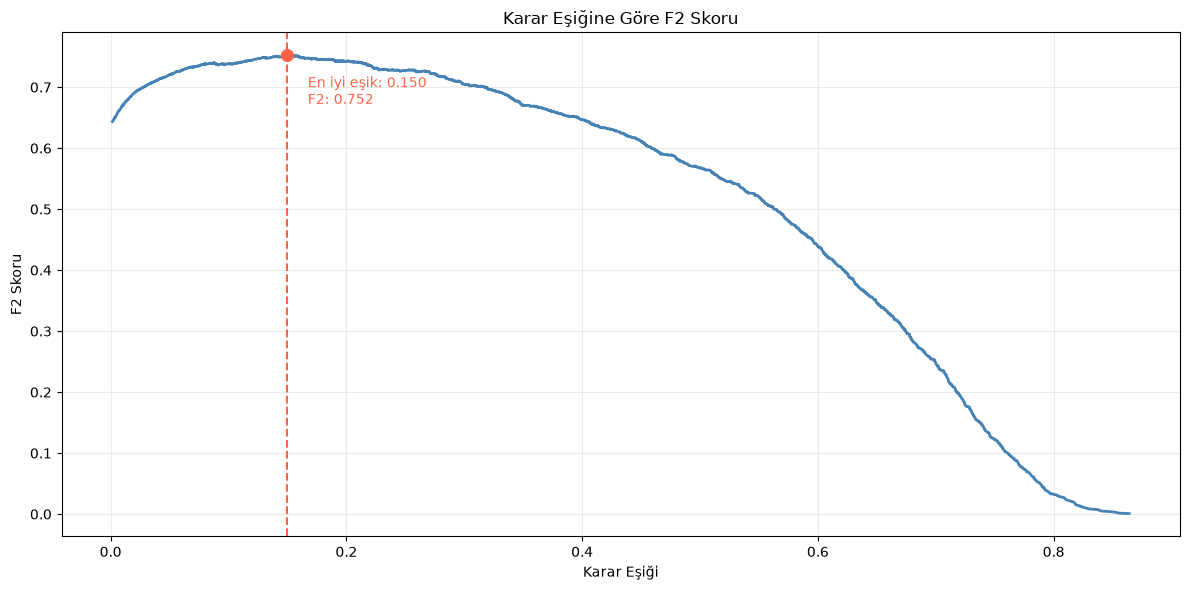

In [71]:
best_index = np.argmax(metric_values)
best_threshold = thresholds[best_index]
best_f2 = metric_values[best_index]

plt.figure(figsize=(12, 6))
plt.plot(thresholds, metric_values, color="steelblue", linewidth=2)
plt.axvline(best_threshold, color="tomato", linestyle="--")
plt.scatter(best_threshold, best_f2, color="tomato", s=70, zorder=3)

plt.annotate(
    f"En iyi eşik: {best_threshold:.3f}\nF2: {best_f2:.3f}",
    xy=(best_threshold, best_f2),
    xytext=(15, -35),
    textcoords="offset points",
    color="tomato"
)

plt.title("Karar Eşiğine Göre F2 Skoru")
plt.xlabel("Karar Eşiği")
plt.ylabel("F2 Skoru")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [72]:
confusion_matrix(y_train,np.where(yes_proba>=thresholds[np.argmax(metric_values)],"Yes","No"))

array([[2401, 1738],
       [ 128, 1367]])

Eğitim tahminlerinde F2 en yüksekken eşik **0,1495644981**, F2 ise **0,7523** çıktı. F2'yi seçtik çünkü ayrılan müşteriyi kaçırmamak bizim için öncelikli ve F2 recall'a daha fazla ağırlık veriyor.

Eşik 0,50'den seçtiğimiz değere inince yakalanan müşteri sayısı 820'den 1.367'ye, yanlış alarm sayısı 427'den 1.738'e çıktı. Yani **547 müşteri daha yakaladık**, bunun karşılığında **1.311 ek yanlış alarm** oluştu. Final testte eğitim verisinden seçtiğimiz eşiğin tam değerini kullandık.

### Final test

In [73]:
final_model = log_gscv

final_model.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [74]:
y_pred = final_model.predict_proba(X_test)
y_pred.shape

(1409, 2)

In [75]:
final_model.classes_

array(['No', 'Yes'], dtype=object)

In [76]:
final_predictions = np.where(y_pred[:,1]>=best_threshold,"Yes","No")
final_predictions

array(['No', 'Yes', 'No', ..., 'Yes', 'No', 'No'],
      shape=(1409,), dtype='<U3')

In [77]:
confusion_matrix(y_test,final_predictions)

array([[598, 437],
       [ 31, 343]])

In [78]:

display(recall_score(y_test,final_predictions,pos_label="Yes"))
display(precision_score(y_test,final_predictions,pos_label="Yes"))
display(fbeta_score(y_test,final_predictions,beta=2,pos_label="Yes"))
display(average_precision_score(y_test,y_pred[:,1],pos_label="Yes"))

0.9171122994652406

0.43974358974358974

0.7535149384885764

0.6337024099769349

Final testte 374 ayrılan müşterinin **343'ünü yakaladık, 31'ini kaçırdık**. Ayrılmayan 1.035 müşteriden **437'si için yanlış alarm** verdik, 598'ini doğru sınıflandırdık.

Recall **%91,71**, precision **%43,97**, F2 **0,754**, AP **0,634**. Yani ayrılan müşterilerin büyük kısmını yakaladık ama 780 uyarının 437'si yanlış alarmdı.